# Pandas guide for machine learning

This notebook explains the pandas operations used in the linear-regression practices. You do not need a statistics background to follow it. Think of a **DataFrame** as an Excel sheet inside Python: rows are cases, columns are fields.

**How to use this guide**
1. Read the short description of the function.
2. Run the example cell.
3. Complete the empty practice cell with a similar idea, using another column or another filter.

The sample table describes **weekly customer orders** in a small company. Any role can read it: sales, operations, support, or analysis.

| Column | Meaning |
|---|---|
| `order_id` | Unique identifier of the order |
| `team` | Team that handled the order: Sales, Support, or Operations |
| `channel` | How the order arrived: Web, Store, or Phone |
| `quantity` | Number of items |
| `unit_price` | Price of one item |
| `delivery_days` | Days from purchase to delivery |
| `satisfaction` | Customer score from 1 to 10 |

In machine learning we usually pick one **target** column to predict (here, `satisfaction`) and use the others as **features**. Pandas prepares the table before any model is trained.


## 0. Load pandas and create a table

`import pandas as pd` loads the library. The alias `pd` is the conventional short name.

`pd.DataFrame({...})` builds a table from a dictionary: each key becomes a column name, each list becomes the values of that column.

`pd.set_option(...)` only changes how numbers are displayed; it does not change the data.

`to_csv` writes the table to a file. `read_csv` is the usual way to load data in a machine-learning project.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

df = pd.DataFrame({
    "order_id": [f"ORD-{i:03d}" for i in range(1, 13)],
    "team": [
        "Sales", "Support", "Operations", "Sales", "Support", "Sales",
        "Operations", "Support", "Sales", "Operations", "Support", "Sales",
    ],
    "channel": [
        "Web", "Phone", "Store", "Web", "Web", "Phone",
        "Store", "Phone", "Web", "Web", "Store", "Phone",
    ],
    "quantity": [2, 1, 5, 3, 2, 4, 1, 2, 6, 3, 1, 2],
    "unit_price": [19.5, 45.0, 12.0, 22.0, 18.0, 30.0, 55.0, 16.5, 10.0, 24.0, 40.0, 28.0],
    "delivery_days": [3, 7, 2, 4, 5, 6, 1, 8, 3, 4, 9, 2],
    "satisfaction": [8, 6, 9, 7, 5, 8, 9, 4, 8, 7, 3, 8],
})

# Intentional quality issues so later sections have something to clean.
df.loc[3, "delivery_days"] = np.nan
df.loc[10, "unit_price"] = 400.0
df = pd.concat([df, df.iloc[[1]]], ignore_index=True)

df.to_csv("sample_orders.csv", index=False)
print("Rows and columns:", df.shape)
df.head(13)


Rows and columns: (13, 7)


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-004,Sales,Web,3,22.00,NaN,7
4,ORD-005,Support,Web,2,18.00,5.00,5
5,ORD-006,Sales,Phone,4,30.00,6.00,8
6,ORD-007,Operations,Store,1,55.00,1.00,9
7,ORD-008,Support,Phone,2,16.50,8.00,4
8,ORD-009,Sales,Web,6,10.00,3.00,8
9,ORD-010,Operations,Web,3,24.00,4.00,7


In [2]:
# PRACTICE CELL — complete this yourself.
# Load sample_orders.csv with pd.read_csv and print its shape.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 1. Inspect the table: `head`, `tail`, `shape`, `columns`, `dtypes`

These functions answer: *what does the table look like?*

- `head(n)` — first n rows (default 5). Use this before any analysis.
- `tail(n)` — last n rows.
- `shape` — tuple `(rows, columns)`. A tuple cannot be edited by accident.
- `columns` — names of the fields.
- `dtypes` — type of each column (`int64`, `float64`, `object` for text).

Machine-learning models need numeric features. `dtypes` tells you which columns are already numbers and which are text.


In [3]:
print("First rows")
display(df.head())

print("Last rows")
display(df.tail(3))

print("shape (rows, columns):", df.shape)
print("column names:", list(df.columns))
print("data types")
display(df.dtypes.to_frame("dtype"))


First rows


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-004,Sales,Web,3,22.00,NaN,7
4,ORD-005,Support,Web,2,18.00,5.00,5


Last rows


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
10,ORD-011,Support,Store,1,400.00,9.00,3
11,ORD-012,Sales,Phone,2,28.00,2.00,8
12,ORD-002,Support,Phone,1,45.00,7.00,6


shape (rows, columns): (13, 7)
column names: ['order_id', 'team', 'channel', 'quantity', 'unit_price', 'delivery_days', 'satisfaction']
data types


,dtype
order_id,str
team,str
channel,str
quantity,int64
unit_price,float64
delivery_days,float64
satisfaction,int64


In [4]:
# PRACTICE CELL — complete this yourself.
# Show only the first 4 rows, then list the column names as a Python list.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 2. Select columns: `[]` and `loc`

You rarely need every column at once.

- `df["satisfaction"]` — one column. The result is a **Series** (one list with an index).
- `df[["team", "satisfaction"]]` — several columns. Pass a **list**. The result stays a DataFrame.
- `df.loc[:, ["team", "satisfaction"]]` — same idea with `loc`. The first position is rows (`:` means all rows), the second is columns.

In the previous notebooks we stored column names in a **tuple** so the list of features was fixed, then converted it with `list(...)` because pandas expects a list for several columns.


In [5]:
# One column -> Series
satisfaction = df["satisfaction"]
print("Type of one column:", type(satisfaction))
display(satisfaction.head())

# Several columns from a tuple of names
feature_tuple = ("quantity", "unit_price", "delivery_days")
features = df.loc[:, list(feature_tuple)]
display(features.head())


Type of one column: <class 'pandas.Series'>


0    8
1    6
2    9
3    7
4    5
Name: satisfaction, dtype: int64

,quantity,unit_price,delivery_days
0,2,19.50,3.00
1,1,45.00,7.00
2,5,12.00,2.00
3,3,22.00,NaN
4,2,18.00,5.00


In [6]:
# PRACTICE CELL — complete this yourself.
# Select channel and satisfaction with loc. Store the column names in a tuple first.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 3. Filter rows: boolean masks, `&`, `between`, `query`

A **filter** keeps only the rows that match a condition. This is how you study a subgroup before training a model.

- `df["satisfaction"] >= 8` produces True/False for every row (a mask).
- `df[mask]` keeps the True rows.
- Combine conditions with `&` (and) and `|` (or). Each condition must be inside parentheses.
- `between(low, high)` checks an inclusive numeric range.
- `query("satisfaction >= 8")` writes the same idea as a short text expression.

A filter does **not** prove that one field causes another. It only describes a subset.


In [7]:
high_score = df[df["satisfaction"] >= 8]
print("Orders with satisfaction >= 8:", len(high_score))

web_and_fast = df[(df["channel"] == "Web") & (df["delivery_days"] <= 4)]
print("Web orders delivered in 4 days or less:", len(web_and_fast))

typical_price = df[df["unit_price"].between(10, 50)]
print("Orders with a typical unit price:", len(typical_price))

same_with_query = df.query("channel == 'Web' and satisfaction >= 7")
display(same_with_query[["order_id", "channel", "satisfaction"]])


Orders with satisfaction >= 8:

 6
Web orders delivered in 4 days or less: 3
Orders with a typical unit price: 11


,order_id,channel,satisfaction
0,ORD-001,Web,8
3,ORD-004,Web,7
8,ORD-009,Web,8
9,ORD-010,Web,7


In [8]:
# PRACTICE CELL — complete this yourself.
# Filter Support team orders with satisfaction below 6. Then rewrite the same filter with query.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 4. Group results: `groupby` and `agg`

`groupby("team")` splits the table by category. `agg(...)` calculates a summary inside each group.

This is useful in machine learning to see whether the target behaves differently across groups (for example, satisfaction by channel). Unequal group sizes matter: a mean based on 2 rows is less stable than a mean based on 40 rows.


In [9]:
by_team = df.groupby("team").agg(
    n_orders=("order_id", "count"),
    average_satisfaction=("satisfaction", "mean"),
    median_delivery=("delivery_days", "median"),
).sort_values("average_satisfaction", ascending=False)

by_team


,n_orders,average_satisfaction,median_delivery
team,,,
Operations,3,8.33,2.00
Sales,5,7.80,3.00
Support,5,4.80,7.00


In [10]:
# PRACTICE CELL — complete this yourself.
# Group by channel. For each channel show the number of orders and the mean unit_price.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 5. Find incomplete data: `isna` and `dropna`

`NaN` means “not a number”: the value is missing.

- `df.isna()` — True where a cell is missing.
- `df.isna().sum()` — count of missing values per column.
- `dropna()` — remove rows that contain at least one missing value.

Missing values break most linear-regression functions. You must either drop those rows or fill them. In a first course, dropping a few incomplete rows is acceptable if you document the decision.


In [11]:
print("Missing values per column")
display(df.isna().sum().to_frame("missing"))

print("Rows that have at least one missing value")
display(df[df.isna().any(axis=1)])


Missing values per column


,missing
order_id,0
team,0
channel,0
quantity,0
unit_price,0
delivery_days,1
satisfaction,0


Rows that have at least one missing value


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
3,ORD-004,Sales,Web,3,22.00,NaN,7


In [12]:
# PRACTICE CELL — complete this yourself.
# Count missing values only in delivery_days. Then create a copy without missing rows using dropna().
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 6. Find repeated rows: `duplicated` and `drop_duplicates`

A duplicate is a row that appears more than once. Duplicates inflate counts and can bias a model toward that repeated case.

- `duplicated().sum()` — how many extra copies exist (the first copy is not counted).
- `drop_duplicates()` — keep one copy of each unique row.


In [13]:
print("Extra duplicate rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])


Extra duplicate rows: 1


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
1,ORD-002,Support,Phone,1,45.00,7.00,6
12,ORD-002,Support,Phone,1,45.00,7.00,6


In [14]:
# PRACTICE CELL — complete this yourself.
# Create clean_no_dup by dropping duplicates. Print the number of rows before and after.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 7. Find values outside a valid range: `between` and masks

In the graphic-design notebook, scores had to stay inside 1–10. Here, `unit_price` should be a realistic amount and `satisfaction` should stay inside 1–10.

`~` means “not”. `~series.between(a, b)` flags values outside the interval.

Out-of-range values create large gaps in plots and can pull a regression line toward an extreme point. Remove them only when you have a clear rule (for example: “price cannot be 400 in this catalog”).


In [15]:
price_ok = df["unit_price"].between(1, 100)
score_ok = df["satisfaction"].between(1, 10)
invalid = df[~price_ok | ~score_ok]
print("Rows outside the agreed range")
display(invalid)


Rows outside the agreed range

,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
10,ORD-011,Support,Store,1,400.00,9.00,3


In [16]:
# PRACTICE CELL — complete this yourself.
# Flag rows where delivery_days is not between 1 and 10. Display those rows.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 8. Build a clean copy: `copy`, `drop_duplicates`, `dropna`, `reset_index`

Never overwrite the original `df` until you have inspected the problems. `.copy()` makes an independent table.

`reset_index(drop=True)` rebuilds the row numbers from 0, 1, 2, ... after you delete rows. That avoids holes in the index.


In [17]:
# copy() keeps the original df unchanged.
clean_df = df.drop_duplicates().dropna().copy()
clean_df = clean_df[clean_df["unit_price"].between(1, 100)].copy()
clean_df = clean_df.reset_index(drop=True)

print("Original rows:", len(df))
print("Clean rows:", len(clean_df))
clean_df


Original rows:

 13
Clean rows: 10


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-005,Support,Web,2,18.00,5.00,5
4,ORD-006,Sales,Phone,4,30.00,6.00,8
5,ORD-007,Operations,Store,1,55.00,1.00,9
6,ORD-008,Support,Phone,2,16.50,8.00,4
7,ORD-009,Sales,Web,6,10.00,3.00,8
8,ORD-010,Operations,Web,3,24.00,4.00,7
9,ORD-012,Sales,Phone,2,28.00,2.00,8


In [18]:
# PRACTICE CELL — complete this yourself.
# From df, create your own clean_df: drop duplicates, drop missing values, keep unit_price between 1 and 100, then reset_index.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 9. Summary numbers: `describe`, `min`, `max`, `mean`, `median`, `std`

These are the core descriptive statistics used before a model:

- **min / max** — observed range.
- **mean** — arithmetic average; sensitive to extreme values.
- **median** — middle value after sorting; more resistant to extremes.
- **std** — how spread out the numbers are around the mean.
- **count** — how many non-missing values were used.

`describe()` computes them together. `.T` transposes the table so each variable is a row, which is easier to read.


In [19]:
numeric_columns = ["quantity", "unit_price", "delivery_days", "satisfaction"]
summary = clean_df[numeric_columns].describe().T
summary = summary.rename(columns={
    "count": "n",
    "mean": "mean",
    "std": "std_dev",
    "min": "min",
    "25%": "Q1",
    "50%": "median",
    "75%": "Q3",
    "max": "max",
})
summary["range"] = summary["max"] - summary["min"]
summary


,n,mean,std_dev,min,Q1,median,Q3,max,range
quantity,10.00,2.80,1.69,1.00,2.00,2.00,3.75,6.00,5.00
unit_price,10.00,25.80,14.43,10.00,16.88,21.75,29.50,55.00,45.00
delivery_days,10.00,4.10,2.33,1.00,2.25,3.50,5.75,8.00,7.00
satisfaction,10.00,7.20,1.69,4.00,6.25,8.00,8.00,9.00,5.00


In [20]:
# PRACTICE CELL — complete this yourself.
# Compute mean, min, and max of satisfaction on clean_df without using describe(). You can use clean_df['satisfaction'].mean().
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 10. Rename columns: `rename`

`rename(columns={old: new})` changes labels. Clear names matter when you later write `df["satisfaction"]` in a model.

Use this after `describe()` if you want labels such as `median` instead of `50%`.


In [21]:
renamed = clean_df.rename(columns={"unit_price": "price_per_item"})
print(list(renamed.columns))
renamed.head(3)


['order_id', 'team', 'channel', 'quantity', 'price_per_item', 'delivery_days', 'satisfaction']


,order_id,team,channel,quantity,price_per_item,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9


In [22]:
# PRACTICE CELL — complete this yourself.
# Rename satisfaction to customer_score on a copy. Do not overwrite clean_df.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 11. Correlation: `corr`

`corr()` measures **linear** association between numeric columns, from −1 to 1.

- Near +1: both tend to increase together.
- Near −1: one tends to fall when the other rises.
- Near 0: no clear straight-line relationship.

Correlation is not causation. It is a first clue for which feature to use in a simple linear regression.


In [23]:
correlations = clean_df[numeric_columns].corr()
display(correlations)

with_target = correlations["satisfaction"].drop("satisfaction")
with_target.sort_values(key=abs, ascending=False).to_frame("correlation_with_satisfaction")


,quantity,unit_price,delivery_days,satisfaction
quantity,1.00,-0.67,-0.19,0.37
unit_price,-0.67,1.00,-0.07,0.18
delivery_days,-0.19,-0.07,1.00,-0.83
satisfaction,0.37,0.18,-0.83,1.00


,correlation_with_satisfaction
delivery_days,-0.83
quantity,0.37
unit_price,0.18


In [24]:
# PRACTICE CELL — complete this yourself.
# Which numeric column has the strongest absolute correlation with satisfaction? Store its name in most_related.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 12. Cut a numeric column into groups: `pd.cut`

`pd.cut(series, bins=3, labels=...)` converts a number into Low / Medium / High groups. Then `groupby` can compare the target across those groups.

This is the same idea as filtering, but the groups are created from a numeric scale instead of a category that already exists.


In [25]:
clean_df = clean_df.copy()
clean_df["delivery_group"] = pd.cut(
    clean_df["delivery_days"],
    bins=3,
    labels=["fast", "medium", "slow"],
)
clean_df.groupby("delivery_group", observed=True).agg(
    n=("order_id", "count"),
    average_satisfaction=("satisfaction", "mean"),
)


,n,average_satisfaction
delivery_group,,
fast,5,8.40
medium,2,6.00
slow,3,6.00


In [26]:
# PRACTICE CELL — complete this yourself.
# Create three groups for quantity with pd.cut and compare mean satisfaction in each group.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 13. Combine tables: `pd.concat`

`pd.concat([table_a, table_b], ignore_index=True)` stacks rows. The graphic-design notebook used this to insert a duplicate on purpose.

`ignore_index=True` rebuilds row numbers. Without it, two tables can share the same index values.


In [27]:
extra_row = clean_df.iloc[[0]]
stacked = pd.concat([clean_df.head(2), extra_row], ignore_index=True)
stacked[["order_id", "team", "satisfaction"]]


,order_id,team,satisfaction
0,ORD-001,Sales,8
1,ORD-002,Support,6
2,ORD-001,Sales,8


In [28]:
# PRACTICE CELL — complete this yourself.
# Concatenate the first three rows of clean_df with the last row. Use ignore_index=True.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 14. Apply a function to each column: `apply`

`apply(function, axis=0)` runs a function on every column (axis=0) or every row (axis=1).

In the previous notebooks we used:

```python
df[score_columns].apply(lambda column: column.between(1, 10)).all(axis=1)
```

That means: for each design-score column, check whether values are between 1 and 10; then require that **all** those checks are True in the same row.


In [29]:
score_like = ["quantity", "delivery_days", "satisfaction"]
in_range = clean_df[score_like].apply(lambda column: column.between(0, 10))
print("Per-column range check")
display(in_range.head())
print("Rows where every checked column is in range:", in_range.all(axis=1).sum())


Per-column range check


,quantity,delivery_days,satisfaction
0,True,True,True
1,True,True,True
2,True,True,True
3,True,True,True
4,True,True,True


Rows where every checked column is in range: 10


In [30]:
# PRACTICE CELL — complete this yourself.
# Use apply to test whether quantity, delivery_days, and satisfaction are all >= 1 in each row.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 15. Charts used before modeling: histogram and scatter

A **histogram** (`hist`) shows how values are distributed. A **scatter plot** (`scatter`) shows one variable versus another. The red line from `np.polyfit` is a quick straight-line sketch, not yet the trained model.

`plt.subplots` creates several plots in a grid. `zip(axes.flat, columns)` assigns one column to each panel.


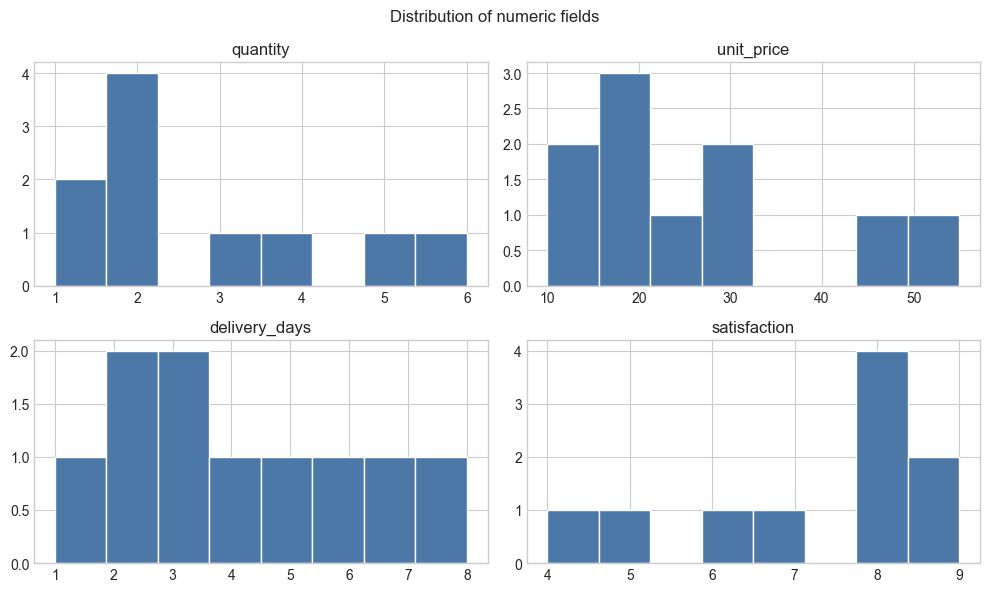

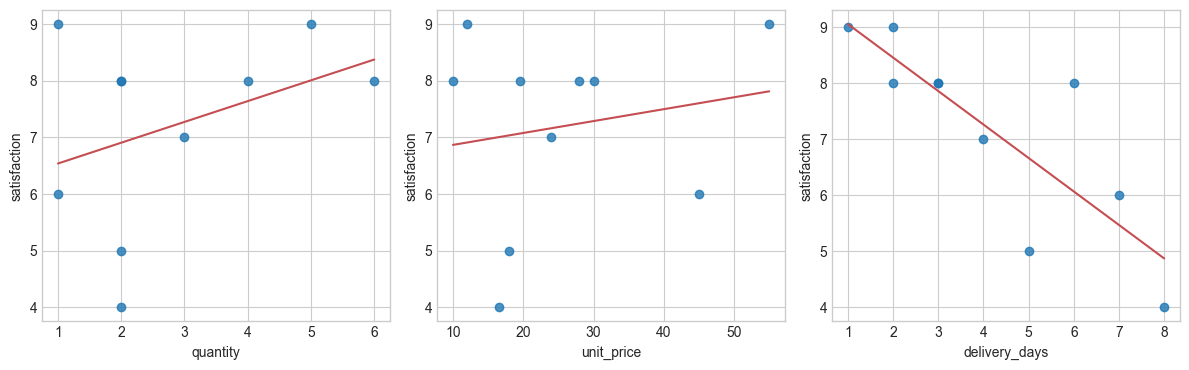

In [31]:
clean_df[numeric_columns].hist(figsize=(10, 6), bins=8, color="#4C78A8", edgecolor="white")
plt.suptitle("Distribution of numeric fields")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, column in zip(axes, ["quantity", "unit_price", "delivery_days"]):
    ax.scatter(clean_df[column], clean_df["satisfaction"], alpha=0.8)
    slope, intercept = np.polyfit(clean_df[column], clean_df["satisfaction"], 1)
    x_line = np.linspace(clean_df[column].min(), clean_df[column].max(), 50)
    ax.plot(x_line, intercept + slope * x_line, color="#C44E52")
    ax.set_xlabel(column)
    ax.set_ylabel("satisfaction")
plt.tight_layout()
plt.show()


In [32]:
# PRACTICE CELL — complete this yourself.
# Draw a scatter plot of delivery_days (X) versus satisfaction (Y). Add axis labels.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 16. From a clean table to a simple model (scikit-learn)

After pandas has prepared the table, scikit-learn can estimate a line.

- `train_test_split` reserves some rows to test the model on data it did not use to learn.
- `LinearRegression().fit(X, y)` estimates intercept and slope.
- `predict` produces estimated target values.
- `mean_absolute_error`, RMSE, and `r2_score` measure how close those estimates are.

`X` must be a DataFrame of features. `y` is the target Series. That is why we write `clean_df[["delivery_days"]]` with double brackets.


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

X = clean_df[["delivery_days"]]
y = clean_df["satisfaction"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"satisfaction ≈ {model.intercept_:.2f} + ({model.coef_[0]:.2f} × delivery_days)")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2:", round(r2_score(y_test, y_pred), 3))


satisfaction ≈ 9.85 + (-0.65 × delivery_days)
MAE: 0.384
RMSE: 0.453
R2: 0.868


In [34]:
# PRACTICE CELL — complete this yourself.
# Train the same LinearRegression using unit_price instead of delivery_days. Print intercept, slope, and R2.
# Keep the variables df / clean_df from previous cells. Do not overwrite df
# unless the hint asks you to create a copy.


## 17. Mini dictionary of the functions from the previous notebooks

| Function | Typical use before a model |
|---|---|
| `read_csv` / `to_csv` | Load and save tables |
| `head`, `shape`, `dtypes` | First inspection |
| `loc`, list/tuple of names | Select features |
| boolean mask, `&`, `query`, `between` | Study subgroups and valid ranges |
| `groupby` + `agg` | Compare the target across categories |
| `isna`, `dropna` | Handle incomplete rows |
| `duplicated`, `drop_duplicates` | Remove repeated rows |
| `copy`, `reset_index` | Keep a safe cleaned table |
| `describe`, `mean`, `median`, `min`, `max`, `std` | Summarize scale and center |
| `rename` | Clear column names |
| `corr` | Rank linear associations with the target |
| `pd.cut` | Turn a number into groups |
| `pd.concat` | Stack tables |
| `apply` | Repeat a check on several columns |
| `hist`, `scatter` | See distributions and relationships |
| `train_test_split`, `LinearRegression` | Estimate and evaluate a line |

When you return to `graphic_post_impact_student.ipynb`, each `TODO` matches one of these functions.
